<a href="https://colab.research.google.com/github/sivasai-jonnadula/docs/blob/main/CN7031_Week6_Spark_DataSource_RDD_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN7031 · Week 6 — Spark Data Source API and Spark RDDs: KDD Cup 99 Analysis

---

**Practical lab workbook | Big Data Analytics (CN7031) 2026-27**
**Dr Fahimeh Jafari** : [F.Jafari@uel.ac.uk](mailto:F.Jafari@uel.ac.uk)

---

### Learning outcomes
By the end of this lab, you should be able to:
1. Read and write data in different formats (CSV, JSON, Parquet) with the **Spark Data Source API**.
2. Use **Spark SQL** for the analysis of a real network-security dataset.
3. **Visualise** the results of queries as bar and pie charts, with linear and logarithmic scales.
4. Work with **RDDs**: create them, transform them with `map`, `filter` and `reduceByKey`, and convert between RDDs and DataFrames.
5. Explain how Spark splits data into **partitions**, and how file formats and partitioned folders make queries faster.

### The Data Source API
Spark reads and writes every kind of data through one interface, the **Data Source API**. Whatever the format, the pattern is the same:

```python
spark.read.format("csv").option("header", True).schema(...).load("path")     # read
df.write.format("parquet").mode("overwrite").partitionBy("col").save("path")  # write
```

| Part | Meaning |
| :-- | :-- |
| `format(…)` | The source: `csv`, `json`, `parquet`, `orc`, `text`, `jdbc` (databases), and more through plug-ins (e.g. Avro, Delta, Kafka) |
| `option(…)` | Settings for that format, e.g. `header`, `inferSchema`, `sep`, `compression` |
| `schema(…)` | The column names and types, given by you instead of guessed by Spark |
| `load(…)` / `save(…)` | Where the data is: a local path, `hdfs://…`, `s3a://…` |
| `mode(…)` | What to do if the output already exists: `overwrite`, `append`, `ignore` or `error` |

Shortcuts such as `spark.read.csv(…)` and `df.write.parquet(…)` call the same API.

### RDDs
A **Resilient Distributed Dataset (RDD)** is Spark's basic data structure: a collection of items, split into **partitions** across the machines of a cluster. A DataFrame is built on top of an RDD and adds a **schema** (named, typed columns) that lets Spark optimise queries.

| | RDD | DataFrame |
| :-- | :-- | :-- |
| One record | Any Python object, e.g. a list of fields `['0', 'tcp', 'http', …]` | A row with named, typed columns |
| You write | Functions: `map(lambda f: …)`, `filter(…)`, `reduceByKey(…)` | Column operations or SQL |
| Optimised by Catalyst | No: Spark runs exactly what you wrote | Yes |
| Use it for | Unstructured data and full low-level control | Almost everything else |

### The dataset
**KDD Cup 1999** was the dataset of the Third International Knowledge Discovery and Data Mining Tools Competition. The task was to build a **network intrusion detector**: a model that tells **bad** connections (intrusions or attacks) from **normal** ones. Each record describes one network connection in a simulated military network, with 41 features and a label. This lab uses the **10% sample**: 494,021 connections, about 2 MB compressed.

### How to use the notebook
- Use **Google Colab → Python 3 → CPU**. Run the cells in order, starting from Section 1. On a fresh runtime, Section 1 takes about 2–3 minutes.
- No upload is needed: Step 1.2 downloads the dataset.
- The code cells are **Python**. Each one starts with a comment line (`#`) that says what it does.
- Spark runs in **local mode** on this one Colab VM: the same code would run unchanged on a cluster of hundreds of machines.

**Important:** Colab storage is temporary and is deleted when its runtime resets. If that happens, run Section 1 again.

## 1. Getting ready

**Goal:** Install Spark, download the data, and start a SparkSession.

### 1.1 Install Java and Spark

**Goal:** Spark runs on the **Java Virtual Machine**, so it needs Java. **PySpark** is the Python package that contains Spark itself and lets you drive it from Python. This cell installs Java 17 and PySpark 4.0.4.

**Expected output:** a line starting `openjdk version "17…`, then `PySpark 4.0.4 is installed ✓  Java 17 is ready ✓`.

In [1]:
# @title ▶ 1.1 Install Java 17 and Apache Spark (PySpark 4.0.4)
# Import the tools used to run installation commands and check the result.
import os
import subprocess
import sys
from pathlib import Path

# Spark runs on the Java Virtual Machine; Spark 4 needs Java 17 or newer.
SPARK_VERSION = '4.0.4'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=900):
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=timeout)
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    return p.stdout

# Install Java 17 only when it is not already on this VM.
if not (JAVA / 'bin/java').exists():
    print('Installing Java 17 …')
    checked(['apt-get', 'update', '-qq'])
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Point Spark at Java 17.
os.environ['JAVA_HOME'] = str(JAVA)
os.environ['PATH'] = f'{JAVA}/bin:' + os.environ['PATH']

# Install the PySpark package (Spark itself is bundled inside it), only if this version is missing.
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('pyspark')
except PackageNotFoundError:
    installed = None
if installed != SPARK_VERSION:
    print(f'Installing PySpark {SPARK_VERSION} (about 450 MB) …')
    checked([sys.executable, '-m', 'pip', 'install', '-q', f'pyspark=={SPARK_VERSION}'])
    if 'pyspark' in sys.modules:
        print('An older PySpark was already loaded: choose Runtime → Restart session, then run this cell again.')

# Spark's own log messages (INFO and WARN) would fill the cell outputs: show only errors.
SPARK_CONF = Path('/content/spark-conf')
SPARK_CONF.mkdir(parents=True, exist_ok=True)
(SPARK_CONF / 'log4j2.properties').write_text(
    'rootLogger.level = error\n'
    'rootLogger.appenderRef.stdout.ref = console\n'
    'appender.console.type = Console\n'
    'appender.console.name = console\n'
    'appender.console.target = SYSTEM_ERR\n'
    'appender.console.layout.type = PatternLayout\n'
    'appender.console.layout.pattern = %p %c{1}: %m%n\n'
    'logger.repl.name = org.apache.spark.repl.Main\n'
    'logger.repl.level = error\n')
os.environ['SPARK_CONF_DIR'] = str(SPARK_CONF)

# Java's start-up notices go to a log file instead of the notebook (Spark errors still appear in Python).
import pyspark.java_gateway as java_gateway
if not getattr(java_gateway.Popen, 'quiet', False):
    start_java = java_gateway.Popen
    def quiet_popen(command, **kwargs):
        kwargs.setdefault('stderr', open(SPARK_CONF / 'java.log', 'ab'))
        return start_java(command, **kwargs)
    quiet_popen.quiet = True
    java_gateway.Popen = quiet_popen

# When a query has a mistake, show only Python's short error message, not an extra JSON log of it.
from pyspark.logger import PySparkLogger
for name in ('SQLQueryContextLogger', 'DataFrameQueryContextLogger'):
    PySparkLogger.getLogger(name).disabled = True

# Show what was installed.
java_version = checked([str(JAVA / 'bin/java'), '-version']).splitlines()[0]
print(java_version)
print(f'PySpark {SPARK_VERSION} is installed ✓  Java 17 is ready ✓')

Installing Java 17 …
Installing PySpark 4.0.4 (about 450 MB) …
openjdk version "17.0.20.1" 2026-08-18
PySpark 4.0.4 is installed ✓  Java 17 is ready ✓


### 1.2 Download the dataset

**Goal:** Retrieve the KDD Cup 99 data from its URL. The `urllib.request` module defines functions and classes that help in opening URLs; `urlretrieve` downloads a file and saves it under the name you give.

The cell tries the official UCI site first. If it is not available, it tries two copies of the same file. Opening the file with `gzip` checks that a real compressed data file arrived, not an error page.

**Expected:** `Downloaded from …`, then the file `kddcup.data_10_percent.gz`, of about 2.1 MB.

*The full dataset (4.9 million connections, 18 MB compressed) is at `http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data.gz`. You can use it instead, but each step takes about ten times longer and your numbers will differ from the Expected lines.*

In [3]:
# Download the KDD Cup 99 data (the 10% sample), trying the official UCI site first.
import urllib.request
import gzip
import socket
socket.setdefaulttimeout(60)
urls = ["http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz",
        "https://www.dropbox.com/s/qz62t2oyllkl32s/kddcup.data_10_percent.gz?dl=1",
        "https://raw.githubusercontent.com/ansvad/pyspark/master/kddcup.data_10_percent.gz"]
for url in urls:
    try:
        urllib.request.urlretrieve(url, "kddcup.data_10_percent.gz")
        with gzip.open("kddcup.data_10_percent.gz") as f:
            f.readline()
        print("Downloaded from", url.split("/")[2])
        break
    except Exception as error:
        print("Not available:", url.split("/")[2], "-", type(error).__name__)
!ls -lh kddcup.data_10_percent.gz

Not available: kdd.ics.uci.edu - HTTPError
Downloaded from www.dropbox.com
-rw-r--r-- 1 root root 2.1M Nov  6 09:51 kddcup.data_10_percent.gz


### 1.3 Start a SparkSession

**Goal:** Create the **SparkSession**, the entry point to all Spark functionality, as in Week 5. `local[*]` runs Spark on this machine, using all its CPU cores as parallel workers.

**Expected output:** the Spark version, `4.0.4`, and `local[*]`.

In [4]:
# Create the SparkSession, then show its version and where it runs.
from pyspark.sql import SparkSession

# Create the SparkSession
spark = SparkSession.builder \
    .appName("KDD_Cup_99_Analysis") \
    .master("local[*]") \
    .getOrCreate()

# Show its version and where it runs
print("Spark Version:", spark.version)
print("Master:", spark.sparkContext.master)

Spark Version: 4.0.4
Master: local[*]


## 2. Understand the KDD Cup 99 dataset

**Goal:** As big data specialists, we first read and understand the features of a dataset, and only then analyse or model it.

- The features are described [here](http://kdd.ics.uci.edu/databases/kddcup99/task.html).
- You can find more about the dataset [here](http://kdd.ics.uci.edu/databases/kddcup99/kddcup99.html).

The data is a **CSV file without a header**, compressed with gzip. `zcat` prints a compressed file as text, and `head -n 3` keeps the first three lines: each line is one connection, with 42 comma-separated values. `head` stops reading after three lines, and `zcat` would then complain that it cannot write the rest; `2>/dev/null` hides that harmless message.

**Expected:** three normal `tcp` connections to the `http` service, each ending with the label `normal.`

In [5]:
# Show the first three connections in the compressed file.
!zcat kddcup.data_10_percent.gz 2>/dev/null | head -n 3

0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,9,9,1.00,0.00,0.11,0.00,0.00,0.00,0.00,0.00,normal.
0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,19,19,1.00,0.00,0.05,0.00,0.00,0.00,0.00,0.00,normal.
0,tcp,http,SF,235,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,29,29,1.00,0.00,0.03,0.00,0.00,0.00,0.00,0.00,normal.


### 2.1 The 42 features

The first 41 features describe the connection, and the last one, `connection_status`, is the **label**: `normal.` or the name of an attack. Every label ends with a full stop in the file, e.g. `normal.` and `smurf.`

| # | Feature | Description | Type |
| --: | :-- | :-- | :-- |
| 1 | `duration` | Length (number of seconds) of the connection | continuous |
| 2 | `protocol_type` | Type of the protocol, e.g. tcp, udp, icmp | symbolic |
| 3 | `service` | Network service on the destination, e.g. http, telnet | symbolic |
| 4 | `flag` | Normal or error status of the connection | symbolic |
| 5 | `src_bytes` | Number of data bytes from source to destination | continuous |
| 6 | `dst_bytes` | Number of data bytes from destination to source | continuous |
| 7 | `land` | 1 if the connection is from/to the same host/port; 0 otherwise | symbolic |
| 8 | `wrong_fragment` | Number of "wrong" fragments | continuous |
| 9 | `urgent` | Number of urgent packets | continuous |
| 10 | `hot` | Number of "hot" indicators | continuous |
| 11 | `num_failed_logins` | Number of failed login attempts | continuous |
| 12 | `logged_in` | 1 if successfully logged in; 0 otherwise | symbolic |
| 13 | `num_compromised` | Number of "compromised" conditions | continuous |
| 14 | `root_shell` | 1 if a root shell is obtained; 0 otherwise | continuous |
| 15 | `su_attempted` | 1 if the "su root" command was attempted; 0 otherwise | continuous |
| 16 | `num_root` | Number of "root" accesses | continuous |
| 17 | `num_file_creations` | Number of file creation operations | continuous |
| 18 | `num_shells` | Number of shell prompts | continuous |
| 19 | `num_access_files` | Number of operations on access control files | continuous |
| 20 | `num_outbound_cmds` | Number of outbound commands in an ftp session | continuous |
| 21 | `is_host_login` | 1 if the login belongs to the "host" list; 0 otherwise | symbolic |
| 22 | `is_guest_login` | 1 if the login is a guest login; 0 otherwise | symbolic |
| 23 | `count` | Number of connections to the same host as the current connection in the past two seconds | continuous |
| 24 | `srv_count` | Number of connections to the same service as the current connection in the past two seconds | continuous |
| 25 | `serror_rate` | % of same-host connections that have "SYN" errors | continuous |
| 26 | `srv_serror_rate` | % of same-service connections that have "SYN" errors | continuous |
| 27 | `rerror_rate` | % of same-host connections that have "REJ" errors | continuous |
| 28 | `srv_rerror_rate` | % of same-service connections that have "REJ" errors | continuous |
| 29 | `same_srv_rate` | % of same-host connections to the same service | continuous |
| 30 | `diff_srv_rate` | % of same-host connections to different services | continuous |
| 31 | `srv_diff_host_rate` | % of same-service connections to different hosts | continuous |
| 32 | `dst_host_count` | Number of connections to the same destination host as the current connection, among the last 100 connections | continuous |
| 33 | `dst_host_srv_count` | Number of connections to the same service (port) as the current connection, among the last 100 connections | continuous |
| 34 | `dst_host_same_srv_rate` | % of the connections counted in `dst_host_count` that are to the same service | continuous |
| 35 | `dst_host_diff_srv_rate` | % of the connections counted in `dst_host_count` that are to different services | continuous |
| 36 | `dst_host_same_src_port_rate` | % of the connections counted in `dst_host_srv_count` that come from the same source port | continuous |
| 37 | `dst_host_srv_diff_host_rate` | % of the connections counted in `dst_host_srv_count` that are to different destination hosts | continuous |
| 38 | `dst_host_serror_rate` | % of the connections counted in `dst_host_count` that have "SYN" errors | continuous |
| 39 | `dst_host_srv_serror_rate` | % of the connections counted in `dst_host_srv_count` that have "SYN" errors | continuous |
| 40 | `dst_host_rerror_rate` | % of the connections counted in `dst_host_count` that have "REJ" errors | continuous |
| 41 | `dst_host_srv_rerror_rate` | % of the connections counted in `dst_host_srv_count` that have "REJ" errors | continuous |
| 42 | `connection_status` | The status of the connection (the class label): `normal.` or one of 22 attack types | symbolic |

The 22 attack types are: back, buffer_overflow, ftp_write, guess_passwd, imap, ipsweep, land, loadmodule, multihop, neptune, nmap, perl, phf, pod, portsweep, rootkit, satan, smurf, spy, teardrop, warezclient and warezmaster.

## 3. Read the data with the Data Source API

**Goal:** Create a DataFrame based on the content of the KDD Cup file.

`spark.read.csv(…)` is the CSV shortcut of the Data Source API. Spark recognises the `.gz` ending and **decompresses the file while reading it**: there is no need to unzip it first. The file has no header line, so Spark names the columns `_c0`, `_c1` … `_c41`, and every column is a `string`, because no schema was given and `inferSchema` is off.

**Expected:** 20 rows, with columns `_c0` to `_c41`; the first row starts `0`, `tcp`, `http`, `SF`, `181`, `5450` …

In [7]:
# Create a DataFrame based on the content of the KDD Cup file, and show its first 20 rows.
df = spark.read.csv("kddcup.data_10_percent.gz")
df.show(20)


+---+---+----+---+---+----+---+---+---+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+-------+
|_c0|_c1| _c2|_c3|_c4| _c5|_c6|_c7|_c8|_c9|_c10|_c11|_c12|_c13|_c14|_c15|_c16|_c17|_c18|_c19|_c20|_c21|_c22|_c23|_c24|_c25|_c26|_c27|_c28|_c29|_c30|_c31|_c32|_c33|_c34|_c35|_c36|_c37|_c38|_c39|_c40|   _c41|
+---+---+----+---+---+----+---+---+---+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+-------+
|  0|tcp|http| SF|181|5450|  0|  0|  0|  0|   0|   1|   0|   0|   0|   0|   0|   0|   0|   0|   0|   0|   8|   8|0.00|0.00|0.00|0.00|1.00|0.00|0.00|   9|   9|1.00|0.00|0.11|0.00|0.00|0.00|0.00|0.00|normal.|
|  0|tcp|http| SF|239| 486|  0|  0|  0|  0|   0|   1|   0|   0|   0|   0|   0|   0|   0|   0|   0|   0|   8|   8|0.00|0.00|0.00|0.00|1.00|0.00|0.00|  19|  19|1.00|0.00|0.05

`df.columns` lists the column names.

**Expected:** 42 names, from `'_c0'` to `'_c41'`.

In [8]:
# List the column names.
print(df.columns)

['_c0', '_c1', '_c2', '_c3', '_c4', '_c5', '_c6', '_c7', '_c8', '_c9', '_c10', '_c11', '_c12', '_c13', '_c14', '_c15', '_c16', '_c17', '_c18', '_c19', '_c20', '_c21', '_c22', '_c23', '_c24', '_c25', '_c26', '_c27', '_c28', '_c29', '_c30', '_c31', '_c32', '_c33', '_c34', '_c35', '_c36', '_c37', '_c38', '_c39', '_c40', '_c41']


### 3.1 Rename the columns

**Goal:** Give each column the name of its feature. `withColumnRenamed(old, new)` returns a new DataFrame with one column renamed, so the calls are chained, one per column. DataFrames are never changed in place: the result is saved as a new DataFrame, `df2`.

**Expected:** the 42 feature names, from `'duration'` to `'connection_status'`.

In [9]:
# Rename the 42 columns with the feature names, then list them.
feature_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "connection_status"
]

# Rename the columns one by one from _c0, _c1, ... to their descriptive names
df2 = df
for i, name in enumerate(feature_names):
    df2 = df2.withColumnRenamed(f"_c{i}", name)

# List the renamed columns
print(df2.columns)

['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'connection_status']


## 4. Spark SQL queries and visualisation

**Goal:** To create SQL queries, first register the DataFrame as a SQL **temporary view**, then define the queries on the view. `SELECT *` returns every column.

**Expected:** the same 20 rows as in Section 3, now with the feature names as column headers.

In [10]:
# Register the DataFrame as a SQL temporary view called KddView, then retrieve its content.
df2.createOrReplaceTempView("KddView")
spark.sql("SELECT * FROM KddView").show(20)

+--------+-------------+-------+----+---------+---------+----+--------------+------+---+-----------------+---------+---------------+----------+------------+--------+------------------+----------+----------------+-----------------+-------------+--------------+-----+---------+-----------+---------------+-----------+---------------+-------------+-------------+------------------+--------------+------------------+----------------------+----------------------+---------------------------+---------------------------+--------------------+------------------------+--------------------+------------------------+-----------------+
|duration|protocol_type|service|flag|src_bytes|dst_bytes|land|wrong_fragment|urgent|hot|num_failed_logins|logged_in|num_compromised|root_shell|su_attempted|num_root|num_file_creations|num_shells|num_access_files|num_outbound_cmds|is_host_login|is_guest_login|count|srv_count|serror_rate|srv_serror_rate|rerror_rate|srv_rerror_rate|same_srv_rate|diff_srv_rate|srv_diff_host_ra

Now, you can make some analytical queries on the KDD Cup 99 dataset using Spark SQL. The charts use **pandas** and **Matplotlib**, as in Week 5: `toPandas()` collects a small query result onto this machine, where Python can plot it.

In [12]:
# Import NumPy, Matplotlib and pandas for the charts.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print("pandas",pd.__version__)
print("NumPy",np.__version__)

pandas 2.2.3
NumPy 2.4.6


### 4.1 Query 1: The number of connections for each connection status

**Goal:** `GROUP BY connection_status` makes one group per status, and `count(*)` counts its connections. Spark names the unnamed count column `count(1)`.

**Expected:** `smurf.` has 280,790 connections and `neptune.` 107,201, while some attacks, such as `perl.` (3) and `phf.` (4), appear only a few times. There are 23 statuses, but `show()` prints only the first 20, so `normal.` (97,278), `back.` and `spy.` are not in the list; the chart below shows them all.

In [13]:
# Query 1: List the number of connections for the different connection statuses.
sqlDF = spark.sql("SELECT connection_status, count(*) AS count FROM KddView GROUP BY connection_status")
sqlDF.show()

+-----------------+------+
|connection_status| count|
+-----------------+------+
|     warezmaster.|    20|
|           smurf.|280790|
|             pod.|   264|
|            imap.|    12|
|            nmap.|   231|
|    guess_passwd.|    53|
|         ipsweep.|  1247|
|       portsweep.|  1040|
|           satan.|  1589|
|            land.|    21|
|      loadmodule.|     9|
|       ftp_write.|     8|
| buffer_overflow.|    30|
|         rootkit.|    10|
|     warezclient.|  1020|
|        teardrop.|   979|
|            perl.|     3|
|             phf.|     4|
|        multihop.|     7|
|         neptune.|107201|
+-----------------+------+
only showing top 20 rows


You can present the results visually. `sort_values(by='count(1)', ascending=False)` puts the biggest bars first.

**Expected:** three tall bars (`smurf.`, `neptune.`, `normal.`); all the others are too small to see.

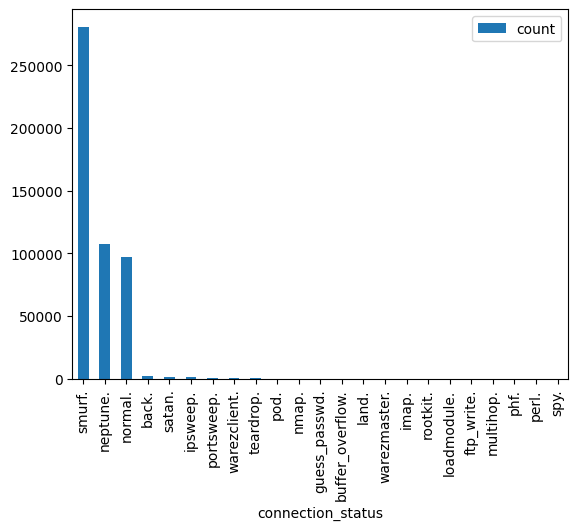

In [20]:
# Plot the number of connections for each status as a bar chart, largest first.
pandas_df = sqlDF.toPandas()
pandas_df.sort_values(by='count', ascending=False).plot(x='connection_status',y='count',kind='bar')
plt.show()

**Why a logarithmic scale?** There are two main reasons to use logarithmic scales in charts and graphs. The first is to respond to **skewness towards large values**, i.e., cases in which one or a few points are much larger than the bulk of the data. The second is to show **percent change** or multiplicative factors. Because of the first reason, we pass `logy=True` to get a log-scale Y axis: each step up the axis is **10 times** the one below (1, 10, 100 …), so small and large counts are visible in the same chart.

**Expected:** every status now has a visible bar, from about 280,000 (`smurf.`) down to 2 (`spy.`).

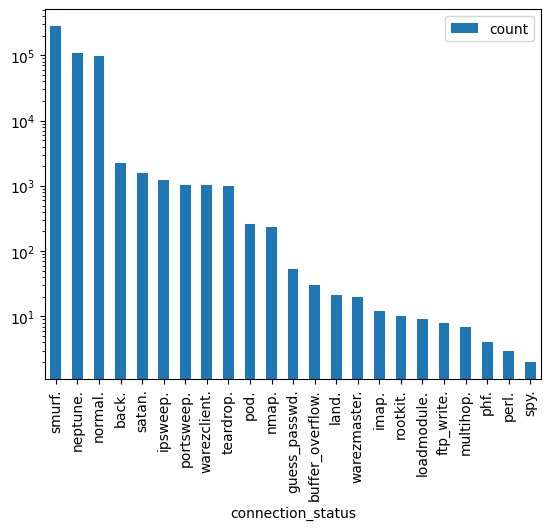

In [21]:
# Plot the same chart with a logarithmic Y axis.
pandas_df.sort_values(by='count', ascending=False).plot(x='connection_status',y='count',kind='bar',logy=True)
plt.show()

### 4.2 Query 2: The number of connections for each protocol type

**Expected:** three protocols: `icmp` (283,602), `tcp` (190,065) and `udp` (20,354).

In [22]:
# Query 2: List the number of connections for each protocol type.
sqlDF = spark.sql("SELECT protocol_type, count(*) AS count FROM KddView GROUP BY protocol_type")
sqlDF.show()

+-------------+------+
|protocol_type| count|
+-------------+------+
|          tcp|190065|
|          udp| 20354|
|         icmp|283602|
+-------------+------+



Extract the visual presentation as below.

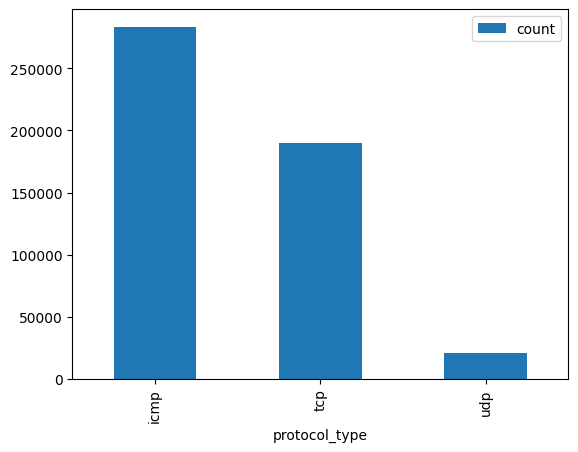

In [23]:
# Plot the number of connections for each protocol type as a bar chart.
pandas_df = sqlDF.toPandas()
pandas_df.sort_values(by='count', ascending=False).plot(x='protocol_type',y='count',kind='bar')
plt.show()

You can use different types of charts. A **pie chart** shows each protocol's share of all connections. `set_index('protocol_type')` uses the protocol names as the slice labels.

**Expected:** `icmp` takes more than half of the pie, `tcp` more than a third, and `udp` a thin slice.

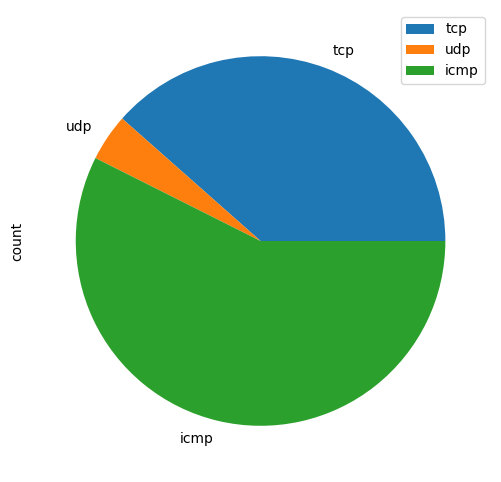

In [24]:
# Plot the protocol types as a pie chart.
pandas_df.set_index('protocol_type').plot(kind='pie', y='count', figsize=(6, 6))
plt.show()

### 4.3 Query 3: The services used for udp connections that are not host logins

**Goal:** `WHERE` keeps the rows that meet both conditions, and `DISTINCT` eliminates duplicate records from the results, so each service is listed once.

**Expected:** five services: `private`, `domain_u`, `ntp_u`, `tftp_u` and `other` (in any order).

In [25]:
# Query 3: List the services used for udp connections that are not host logins.
sqlDF = spark.sql("SELECT DISTINCT service FROM KddView WHERE protocol_type = 'udp' AND is_host_login = 0")
sqlDF.show()

+--------+
| service|
+--------+
|   ntp_u|
|  tftp_u|
|domain_u|
|   other|
| private|
+--------+



### 4.4 Query 4: The number of udp connections for each service, for connections that are not host logins

**Expected:** `private` (8,512), `domain_u` (5,863) and `other` (5,598) have most of the connections; `ntp_u` has 380 and `tftp_u` only 1.

In [26]:
# Query 4: List the number of connections for each service used for udp connections that are not host logins.
sqlDF = spark.sql("SELECT service, count(*) AS count FROM KddView WHERE protocol_type = 'udp' AND is_host_login = 0 GROUP BY service")
sqlDF.show()

+--------+-----+
| service|count|
+--------+-----+
|   ntp_u|  380|
|  tftp_u|    1|
|domain_u| 5863|
|   other| 5598|
| private| 8512|
+--------+-----+



Visual representations:

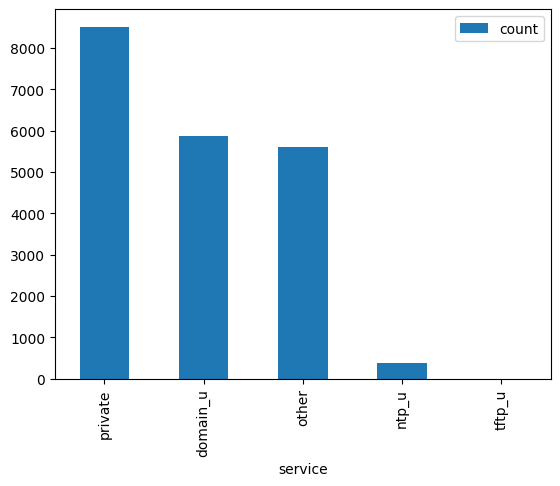

In [27]:
# Plot the udp services as a bar chart.
pandas_df = sqlDF.toPandas()
pandas_df.sort_values(by='count', ascending=False).plot(x='service',y='count',kind='bar')
plt.show()

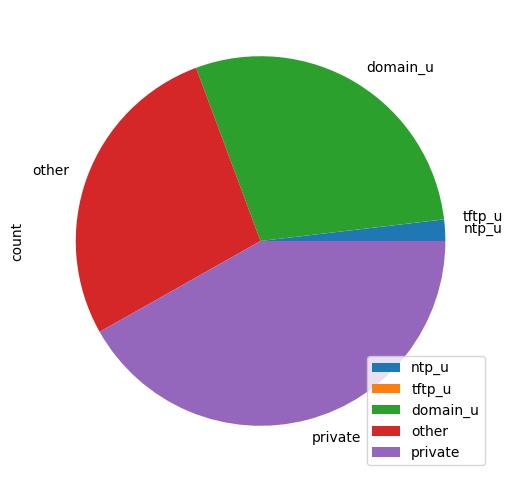

In [28]:
# Plot the udp services as a pie chart.
pandas_df.set_index('service').plot(kind='pie', y='count', figsize=(6, 6))
plt.show()

### 4.5 Query 5: The different types of bad connections

**Goal:** `<>` means "not equal to". Every status except `normal.` is an attack. Note the full stop: the labels in the file are written `normal.`, `smurf.` …

**Expected:** 22 attack types (`show()` prints the first 20).

In [29]:
# Query 5: List the different types of bad connections.
sqlDF = spark.sql("SELECT DISTINCT connection_status FROM KddView WHERE connection_status <> 'normal.'")
sqlDF.show()

+-----------------+
|connection_status|
+-----------------+
|     warezmaster.|
|           smurf.|
|             pod.|
|            imap.|
|            nmap.|
|    guess_passwd.|
|         ipsweep.|
|       portsweep.|
|           satan.|
|            land.|
|      loadmodule.|
|       ftp_write.|
| buffer_overflow.|
|         rootkit.|
|     warezclient.|
|        teardrop.|
|            perl.|
|             phf.|
|        multihop.|
|         neptune.|
+-----------------+
only showing top 20 rows


### 4.6 Query 6: The number of connections for each type of bad connection

**Expected:** the same counts as in Query 1, without `normal.`: `smurf.` (280,790) and `neptune.` (107,201) are by far the most common attacks.

In [30]:
# Query 6: List the number of connections for each type of bad connection.
sqlDF = spark.sql("SELECT connection_status, count(*) AS count FROM KddView WHERE connection_status <> 'normal.' GROUP BY connection_status")
sqlDF.show()

+-----------------+------+
|connection_status| count|
+-----------------+------+
|     warezmaster.|    20|
|           smurf.|280790|
|             pod.|   264|
|            imap.|    12|
|            nmap.|   231|
|    guess_passwd.|    53|
|         ipsweep.|  1247|
|       portsweep.|  1040|
|           satan.|  1589|
|            land.|    21|
|      loadmodule.|     9|
|       ftp_write.|     8|
| buffer_overflow.|    30|
|         rootkit.|    10|
|     warezclient.|  1020|
|        teardrop.|   979|
|            perl.|     3|
|             phf.|     4|
|        multihop.|     7|
|         neptune.|107201|
+-----------------+------+
only showing top 20 rows


Visual representations:

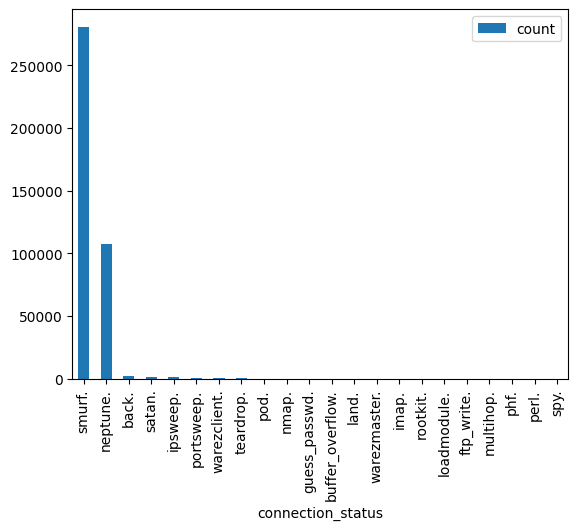

In [31]:
# Plot the bad connections as a bar chart.
pandas_df = sqlDF.toPandas()
pandas_df.sort_values(by='count', ascending=False).plot(x='connection_status',y='count',kind='bar')
plt.show()

Let's use a logarithmic scale for the Y axis.

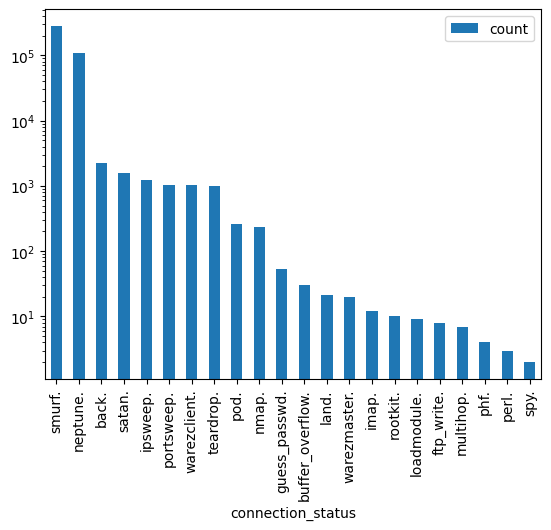

In [32]:
# Plot the bad connections with a logarithmic Y axis.
pandas_df.sort_values(by='count', ascending=False).plot(x='connection_status',y='count',kind='bar',logy=True)
plt.show()

### 4.7 Query 7: The services of tcp connections that received more than 1000 bytes from the destination

**Goal:** `dst_bytes` is the number of bytes sent from the destination back to the source. All the columns of `df2` are strings, so Spark converts `dst_bytes` to a number to compare it with `1000`.

Since there is only one value per row (one column), we cannot use 2D plots here.

**Expected:** 11 services, such as `http`, `ftp`, `telnet` and `smtp`.

In [34]:
# Query 7: List the services of tcp connections that received more than 1000 bytes from the destination.
sqlDF = spark.sql("SELECT DISTINCT service FROM KddView WHERE protocol_type = 'tcp' AND dst_bytes > 1000")
sqlDF.show()

+--------+
| service|
+--------+
|  telnet|
|     ftp|
|     X11|
|   pop_3|
|   login|
|    smtp|
|    http|
|     IRC|
|ftp_data|
|   imap4|
|     ssh|
+--------+



### 4.8 Query 8: The number of tcp connections for each service that received more than 1000 bytes from the destination

**Expected:** `http` has by far the most connections (39,047), then `ftp` (551), `telnet` (239) and `smtp` (168).

In [35]:
# Query 8: List the number of connections for each service, for tcp connections that received more than 1000 bytes.
sqlDF = spark.sql("SELECT service, count(*) AS count FROM KddView WHERE protocol_type = 'tcp' AND dst_bytes > 1000 GROUP BY service")
sqlDF.show()

+--------+-----+
| service|count|
+--------+-----+
|  telnet|  239|
|     ftp|  551|
|     X11|    6|
|   pop_3|   42|
|   login|    2|
|    smtp|  168|
|    http|39047|
|     IRC|   32|
|ftp_data|   36|
|   imap4|    2|
|     ssh|    1|
+--------+-----+



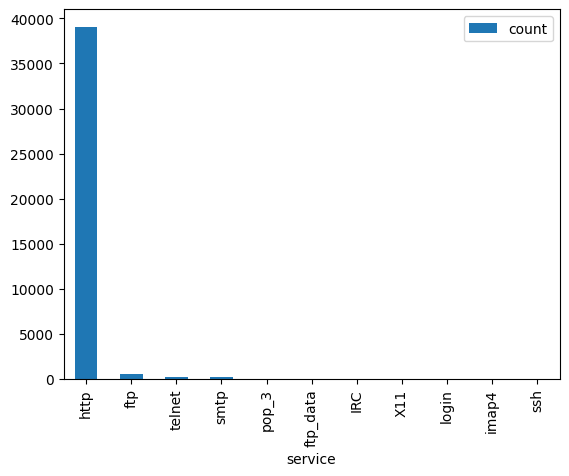

In [36]:
# Plot the services as a bar chart.
pandas_df = sqlDF.toPandas()
pandas_df.sort_values(by='count', ascending=False).plot(x='service',y='count',kind='bar')
plt.show()

Let's use a logarithmic scale for the Y axis.

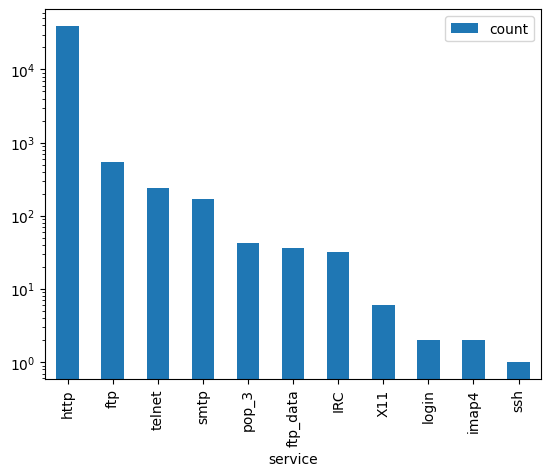

In [37]:
# Plot the services with a logarithmic Y axis.
pandas_df.sort_values(by='count', ascending=False).plot(x='service',y='count',kind='bar',logy=True)
plt.show()

## 5. More of the Data Source API: schemas, formats and partitioned folders

**Goal:** Use the full form of the Data Source API: give it options and a schema, write the data in other formats, and see why the format matters.

### 5.1 Read with options: `format`, `option` and `load`

**Goal:** The shortcut `spark.read.csv(…)` in Section 3 is the same as `spark.read.format("csv").load(…)`. Here an **option** is added: `inferSchema=True` makes Spark read the data once more to **guess each column's type**. `printSchema()` shows the result.

**Expected:** the columns still have no names, but now have types: `_c0` (`duration`), `_c4` (`src_bytes`) and `_c5` (`dst_bytes`) are `integer`, the rates (e.g. `_c24`, `serror_rate`) are `double`, and the text columns `_c1`, `_c2`, `_c3` and `_c41` stay `string`.

In [39]:
# Read the file with the full Data Source API and the inferSchema option, then show the types of the first columns.
df_inferred = spark.read.format("csv").option("inferSchema", "true").load("kddcup.data_10_percent.gz")
df_inferred.select(df_inferred.columns[:6] + ["_c24", "_c41"]).printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- _c1: string (nullable = true)
 |-- _c2: string (nullable = true)
 |-- _c3: string (nullable = true)
 |-- _c4: integer (nullable = true)
 |-- _c5: integer (nullable = true)
 |-- _c24: double (nullable = true)
 |-- _c41: string (nullable = true)



### 5.2 Give the schema yourself

**Goal:** `inferSchema` is convenient, but it costs an extra pass over the whole file, and its guess can be wrong (as with `Value` in Week 5). In production, the schema is usually **given explicitly**: Spark then trusts it and reads the file only once.

A schema is a `StructType`: a list of `StructField(name, type)`, one per column. The cell builds it from the names of `df2`: the four text columns are `StringType`, the rates are `DoubleType`, and all the other columns (durations, bytes, counts and 0/1 flags) are `LongType` (64-bit whole numbers).

**Expected:** 42 typed columns, e.g. `duration: long`, `protocol_type: string`, `serror_rate: double`; and 494,021 rows.

In [42]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, LongType

text_columns = ["protocol_type", "service", "flag", "connection_status"]


kdd_schema = StructType([
    StructField(name, StringType() if name in text_columns else DoubleType() if "rate" in name else LongType(), True)
    for name in df2.columns
])


kdd_typed = spark.read.schema(kdd_schema).csv("./kddcup.data_10_percent.gz")
kdd_typed.printSchema()
print("rows:", kdd_typed.count())

root
 |-- duration: long (nullable = true)
 |-- protocol_type: string (nullable = true)
 |-- service: string (nullable = true)
 |-- flag: string (nullable = true)
 |-- src_bytes: long (nullable = true)
 |-- dst_bytes: long (nullable = true)
 |-- land: long (nullable = true)
 |-- wrong_fragment: long (nullable = true)
 |-- urgent: long (nullable = true)
 |-- hot: long (nullable = true)
 |-- num_failed_logins: long (nullable = true)
 |-- logged_in: long (nullable = true)
 |-- num_compromised: long (nullable = true)
 |-- root_shell: long (nullable = true)
 |-- su_attempted: long (nullable = true)
 |-- num_root: long (nullable = true)
 |-- num_file_creations: long (nullable = true)
 |-- num_shells: long (nullable = true)
 |-- num_access_files: long (nullable = true)
 |-- num_outbound_cmds: long (nullable = true)
 |-- is_host_login: long (nullable = true)
 |-- is_guest_login: long (nullable = true)
 |-- count: long (nullable = true)
 |-- srv_count: long (nullable = true)
 |-- serror_rate: d

### 5.3 Write the data in other formats

**Goal:** `df.write` is the other half of the Data Source API. The same data is written three times: as CSV with a header line, as **JSON** (one object per line) and as **Parquet** (columnar and compressed, see the Week 5 extra lab). `mode("overwrite")` replaces a folder that already exists:

| Mode | If the output already exists |
| :-- | :-- |
| `error` (default) | Stop with an error |
| `overwrite` | Replace it |
| `append` | Add the new rows to it |
| `ignore` | Do nothing |

Spark always writes a **folder**, not a single file: one `part-…` file per partition, and an empty `_SUCCESS` file that marks a complete write.

In [44]:
# Write the typed data as CSV with a header, as JSON and as Parquet.
kdd_typed.write.mode("overwrite").option("header", True).csv("/content/kdd_csv")
kdd_typed.write.mode("overwrite").json("/content/kdd_json")
kdd_typed.write.mode("overwrite").parquet("/content/kdd_parquet")
print("Written✓")

Written✓


`ls` shows the files of the Parquet folder, and `du -sh` the size of each copy.

**Expected:** one `part-…snappy.parquet` file (the data has one partition, see 6.2) and `_SUCCESS`. Then the sizes: the original gzip file 2.1 MB, CSV 66 MB, JSON 406 MB (the column names are repeated in every row) and Parquet only 1.7 MB.

In [46]:
# List the files of the Parquet folder, then compare the size of the four copies.
!ls /content/kdd_parquet
!du -sh kddcup.data_10_percent.gz /content/kdd_csv /content/kdd_json /content/kdd_parquet

part-00000-6c629c7c-d5cc-4706-b207-b6f883181e47-c000.snappy.parquet  _SUCCESS
2.1M	kddcup.data_10_percent.gz
66M	/content/kdd_csv
406M	/content/kdd_json
1.7M	/content/kdd_parquet


### 5.4 Read the other formats back

**Goal:** Reading uses the same API. **Parquet stores the schema inside the file**, so the types come back exactly as written, with no guessing. **JSON** stores the column names with every value: Spark infers the types again, and lists the columns in **alphabetical** order.

**Expected:** both have 494,021 rows. The first two Parquet columns are `duration` (`LongType`) and `protocol_type` (`StringType`), in the original order; the first two JSON columns are `connection_status` (`StringType`) and `count` (`LongType`), in alphabetical order.

In [48]:
# Read the Parquet and JSON copies back, and compare their row counts and first columns.
df_parquet = spark.read.parquet("/content/kdd_parquet")
df_json = spark.read.json("/content/kdd_json")

# Display the schemas to compare column order and types
print("=== Parquet Schema (Maintains original column order) ===")
df_parquet.printSchema()

print("\n=== JSON Schema (Reordered alphabetically) ===")
df_json.printSchema()

# Compare counts and show first few rows
print(f"Parquet row count: {df_parquet.count()}")
print(f"JSON row count: {df_json.count()}")

=== Parquet Schema (Maintains original column order) ===
root
 |-- duration: long (nullable = true)
 |-- protocol_type: string (nullable = true)
 |-- service: string (nullable = true)
 |-- flag: string (nullable = true)
 |-- src_bytes: long (nullable = true)
 |-- dst_bytes: long (nullable = true)
 |-- land: long (nullable = true)
 |-- wrong_fragment: long (nullable = true)
 |-- urgent: long (nullable = true)
 |-- hot: long (nullable = true)
 |-- num_failed_logins: long (nullable = true)
 |-- logged_in: long (nullable = true)
 |-- num_compromised: long (nullable = true)
 |-- root_shell: long (nullable = true)
 |-- su_attempted: long (nullable = true)
 |-- num_root: long (nullable = true)
 |-- num_file_creations: long (nullable = true)
 |-- num_shells: long (nullable = true)
 |-- num_access_files: long (nullable = true)
 |-- num_outbound_cmds: long (nullable = true)
 |-- is_host_login: long (nullable = true)
 |-- is_guest_login: long (nullable = true)
 |-- count: long (nullable = true)
 

**Why Parquet is fast.** A query on Parquet reads only the columns it needs (**column pruning**) and can skip blocks of rows that cannot match (**predicate pushdown**). In the plan, `ReadSchema` lists just the two columns used, and `PushedFilters` holds the condition.

**Expected:** `ReadSchema: struct<service:string,dst_bytes:bigint>` and `PushedFilters: [IsNotNull(dst_bytes), GreaterThan(dst_bytes,1000)]`.

In [49]:
# Show the plan of a query on the Parquet copy.
query_parquet = df_parquet.filter(df_parquet["dst_bytes"] > 1000).select("service")

# Call explain(True) to inspect Catalyst optimizer's physical plan execution
query_parquet.explain(True)

== Parsed Logical Plan ==
'Project ['service]
+- Filter (dst_bytes#1322L > cast(1000 as bigint))
   +- Relation [duration#1317L,protocol_type#1318,service#1319,flag#1320,src_bytes#1321L,dst_bytes#1322L,land#1323L,wrong_fragment#1324L,urgent#1325L,hot#1326L,num_failed_logins#1327L,logged_in#1328L,num_compromised#1329L,root_shell#1330L,su_attempted#1331L,num_root#1332L,num_file_creations#1333L,num_shells#1334L,num_access_files#1335L,num_outbound_cmds#1336L,is_host_login#1337L,is_guest_login#1338L,count#1339L,srv_count#1340L,serror_rate#1341,... 17 more fields] parquet

== Analyzed Logical Plan ==
service: string
Project [service#1319]
+- Filter (dst_bytes#1322L > cast(1000 as bigint))
   +- Relation [duration#1317L,protocol_type#1318,service#1319,flag#1320,src_bytes#1321L,dst_bytes#1322L,land#1323L,wrong_fragment#1324L,urgent#1325L,hot#1326L,num_failed_logins#1327L,logged_in#1328L,num_compromised#1329L,root_shell#1330L,su_attempted#1331L,num_root#1332L,num_file_creations#1333L,num_shells

### 5.5 Partitioned folders: `partitionBy`

**Goal:** `partitionBy("protocol_type")` writes **one folder per value** of a column. A query that filters on that column then reads only the matching folder: this is **partition pruning**, the same idea as Hive's partitioned tables in Week 4.

**Expected:** three folders: `protocol_type=icmp`, `protocol_type=tcp` and `protocol_type=udp`.

In [50]:
# Write the data partitioned by protocol type, then list the folders.
kdd_typed.write.mode("overwrite").partitionBy("protocol_type").parquet("/content/kdd_partitioned")

# List the nested directory structure to verify the partitions
!ls -F /content/kdd_partitioned

'protocol_type=icmp'/  'protocol_type=tcp'/  'protocol_type=udp'/   _SUCCESS


Read the partitioned data and keep only `udp`. `PartitionFilters` in the plan shows that Spark reads only the `protocol_type=udp` folder.

**Expected:** 20,354 udp connections (as in Query 2), and `PartitionFilters: [isnotnull(protocol_type…), (protocol_type… = udp)]`.

In [51]:
# Count the udp connections in the partitioned data, and show the plan.
df_partitioned = spark.read.parquet("/content/kdd_partitioned")

# Query for UDP connections
udp_query = df_partitioned.filter(df_partitioned["protocol_type"] == "udp")

# Print the count to verify
print("UDP connections count:", udp_query.count())

# Show the Spark physical plan to verify partition pruning
udp_query.explain(True)

UDP connections count: 20354
== Parsed Logical Plan ==
'Filter '`=`(protocol_type#1585, udp)
+- Relation [duration#1544L,service#1545,flag#1546,src_bytes#1547L,dst_bytes#1548L,land#1549L,wrong_fragment#1550L,urgent#1551L,hot#1552L,num_failed_logins#1553L,logged_in#1554L,num_compromised#1555L,root_shell#1556L,su_attempted#1557L,num_root#1558L,num_file_creations#1559L,num_shells#1560L,num_access_files#1561L,num_outbound_cmds#1562L,is_host_login#1563L,is_guest_login#1564L,count#1565L,srv_count#1566L,serror_rate#1567,srv_serror_rate#1568,... 17 more fields] parquet

== Analyzed Logical Plan ==
duration: bigint, service: string, flag: string, src_bytes: bigint, dst_bytes: bigint, land: bigint, wrong_fragment: bigint, urgent: bigint, hot: bigint, num_failed_logins: bigint, logged_in: bigint, num_compromised: bigint, root_shell: bigint, su_attempted: bigint, num_root: bigint, num_file_creations: bigint, num_shells: bigint, num_access_files: bigint, num_outbound_cmds: bigint, is_host_login: bi

## 6. Spark RDDs

**Goal:** Work one level below DataFrames, with **RDDs**. The **SparkContext** (`spark.sparkContext`, saved as `sc`) is the entry point for RDDs, as the SparkSession is for DataFrames.

| Operation | Kind | Meaning |
| :-- | :-- | :-- |
| `sc.parallelize(list)` | create | Make an RDD from a Python list |
| `sc.textFile(path)` | create | Make an RDD with one item per line of a text file |
| `map(f)` | transformation | Apply `f` to every item: one item in, one item out |
| `filter(f)` | transformation | Keep the items for which `f` is `True` |
| `reduceByKey(f)` | transformation | For `(key, value)` pairs: combine the values of each key with `f` |
| `distinct()` | transformation | Remove duplicate items |
| `collect()`, `take(n)`, `first()`, `count()`, `reduce(f)` | action | Return results to Python |

As with DataFrames, **transformations are lazy**: nothing runs until an action asks for a result.

### 6.1 Create an RDD from a Python list

**Goal:** `parallelize` splits a list into partitions. `map(lambda x: x * x)` squares each number: a `lambda` is a small function written in one line, here "take `x`, return `x * x`". `collect()` returns all the items, and `reduce` combines them two at a time, here by adding them.

**Expected:** `[1, 4, 9, 16, 25]` and `sum: 55`.

In [52]:
# Create an RDD from a Python list, square each number, and add them up.
sc = spark.sparkContext
rdd = sc.parallelize(range(1, 6))
print(rdd.collect())
print("sum:", rdd.map(lambda x: x * x).reduce(lambda x, y: x + y))

[1, 2, 3, 4, 5]
sum: 55


### 6.2 Create an RDD from the KDD Cup file

**Goal:** `textFile` reads the file as plain lines of text: an RDD has **no schema**, so each item is just one string.

The RDD has only **1 partition**: a gzip file cannot be split, because it must be decompressed from the beginning. On a cluster, a single gzip file is therefore read by one task only. Splittable formats (plain text, Parquet, or many smaller files) let many tasks read in parallel.

**Expected:** 494,021 lines in 1 partition, then the first two lines as strings.

In [53]:
# Read the file as an RDD of text lines, count the lines and partitions, and show the first two.
raw_rdd = sc.textFile("kddcup.data_10_percent.gz")
print("lines:", raw_rdd.count())
print("partitions:", raw_rdd.getNumPartitions())
print("first two:", raw_rdd.take(2))

lines: 494021
partitions: 1
first two: ['0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,9,9,1.00,0.00,0.11,0.00,0.00,0.00,0.00,0.00,normal.', '0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,19,19,1.00,0.00,0.05,0.00,0.00,0.00,0.00,0.00,normal.']


### 6.3 Split the lines into fields with `map`

**Goal:** `map(lambda line: line.split(","))` turns each line into a **list of 42 strings**. There are no column names: the fields are reached by **position**, from `f[0]` (`duration`) to `f[41]` (`connection_status`).

**Expected:** a list starting `['0', 'tcp', 'http', 'SF', '181', '5450', …` and ending with `'normal.'`; 42 fields.

In [54]:
# Split each line into a list of fields, and show the first record.
rows = raw_rdd.map(lambda line: line.split(","))
print(rows.first())
print("fields:", len(rows.first()))

['0', 'tcp', 'http', 'SF', '181', '5450', '0', '0', '0', '0', '0', '1', '0', '0', '0', '0', '0', '0', '0', '0', '0', '0', '8', '8', '0.00', '0.00', '0.00', '0.00', '1.00', '0.00', '0.00', '9', '9', '1.00', '0.00', '0.11', '0.00', '0.00', '0.00', '0.00', '0.00', 'normal.']
fields: 42


### 6.4 Keep the attacks with `filter`

**Goal:** `filter(lambda f: f[41] != "normal.")` keeps the connections whose label is not `normal.`

**Expected:** 396,743 attacks and 97,278 normal connections, adding up to 494,021.

In [55]:
# Count the attack and the normal connections with filter.
attacks = rows.filter(lambda f: f[41] != "normal.")
print("attacks:", attacks.count())
normal = rows.filter(lambda f: f[41] == "normal.")
print("normal:", normal.count())

attacks: 396743
normal: 97278


### 6.5 Count with key-value pairs: `reduceByKey`

**Goal:** This is **MapReduce in Spark**. `map(lambda f: (f[41], 1))` turns each connection into a **(key, value)** pair: (its status, 1). `reduceByKey(lambda a, b: a + b)` brings the pairs with the same key together (a **shuffle**) and adds their values. `sortBy` sorts the result by the count, largest first.

**Expected:** the same numbers as Query 1: `smurf.` 280,790, `neptune.` 107,201, `normal.` 97,278 …

In [56]:
# Count the connections for each status with map and reduceByKey, largest first.
status_counts = rows.map(lambda f: (f[41], 1)).reduceByKey(lambda a, b: a + b).sortBy(lambda f: f[1], False)
status_counts.collect()

[('smurf.', 280790),
 ('neptune.', 107201),
 ('normal.', 97278),
 ('back.', 2203),
 ('satan.', 1589),
 ('ipsweep.', 1247),
 ('portsweep.', 1040),
 ('warezclient.', 1020),
 ('teardrop.', 979),
 ('pod.', 264),
 ('nmap.', 231),
 ('guess_passwd.', 53),
 ('buffer_overflow.', 30),
 ('land.', 21),
 ('warezmaster.', 20),
 ('imap.', 12),
 ('rootkit.', 10),
 ('loadmodule.', 9),
 ('ftp_write.', 8),
 ('multihop.', 7),
 ('phf.', 4),
 ('perl.', 3),
 ('spy.', 2)]

The same pattern answers other questions. Here the value is `int(f[4])`, the bytes sent by the source, so `reduceByKey` adds up the **total bytes for each protocol**. `countByValue()` is a shortcut that counts each different item, and `distinct().count()` counts the different services.

**Expected:** `tcp` 1,229,530,130 bytes, `icmp` 263,272,941 and `udp` 1,911,953; then `tcp` 190,065, `udp` 20,354 and `icmp` 283,602 connections (as in Query 2); and 66 services.

In [58]:
# Total bytes sent for each protocol, connections per protocol, and the number of different services.
bytes_per_protocol = rows.map(lambda f: (f[1], int(f[4]))).reduceByKey(lambda a, b: a + b)
print("Bytes sent per protocol:", bytes_per_protocol.collect())

# 2. Total connection count per protocol type
connections_per_protocol = rows.map(lambda f: f[1]).countByValue()
print("Connections per protocol:", dict(connections_per_protocol))

# 3. Number of distinct services
distinct_services_count = rows.map(lambda f: f[2]).distinct().count()
print("Number of different services:", distinct_services_count)

Bytes sent per protocol: [('tcp', 1229530130), ('udp', 1911953), ('icmp', 263272941)]
Connections per protocol: {'tcp': 190065, 'udp': 20354, 'icmp': 283602}
Number of different services: 66


### 6.6 Lineage and caching

**Goal:** An RDD remembers the steps that created it, its **lineage**. If a partition is lost, Spark rebuilds it by running those steps again: this is what *resilient* means. `toDebugString()` prints the lineage, read from the bottom up: the file, then `map`, then the shuffle of `reduceByKey`.

In [61]:
# Show the lineage of status_counts.
print(status_counts.toDebugString().decode("utf-8"))

(1) PythonRDD[247] at collect at /tmp/ipykernel_1511/2681676958.py:3 []
 |  MapPartitionsRDD[246] at mapPartitions at PythonRDD.scala:169 []
 |  ShuffledRDD[245] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(1) PairwiseRDD[244] at reduceByKey at /tmp/ipykernel_1511/2681676958.py:2 []
    |  PythonRDD[243] at reduceByKey at /tmp/ipykernel_1511/2681676958.py:2 []
    |  kddcup.data_10_percent.gz MapPartitionsRDD[236] at textFile at NativeMethodAccessorImpl.java:0 []
    |  kddcup.data_10_percent.gz HadoopRDD[235] at textFile at NativeMethodAccessorImpl.java:0 []


Every action runs the whole lineage again, from reading the file. `cache()` asks Spark to **keep an RDD in memory** after the next action computes it, so later actions start from memory.

**Expected:** the first count reads and splits the file (about 3 seconds); the second, from memory, takes under a second. Your times will differ.

In [62]:
# Keep rows in memory, then time the same count twice.
import time
rows.cache()
for run in (1,2):
  start = time.time()
  n = rows.count()
  print(f"run {run}: {n} rows in {time.time() - start:.2f} s")

run 1: 494021 rows in 3.58 s
run 2: 494021 rows in 0.74 s


### 6.7 From DataFrame to RDD, and back

**Goal:** Every DataFrame has an RDD underneath: `df2.rdd` returns it, as an RDD of `Row` objects (rows with field names). In the other direction, `spark.createDataFrame(rdd, [names])` gives an RDD of tuples a schema, so it can be queried with DataFrame operations or SQL again.

**Expected:** a `Row(duration='0', protocol_type='tcp', …)`; then the status counts from 6.5 as a table, `smurf.` first.

In [60]:
# Get the RDD underneath df2, then turn the status counts RDD into a DataFrame.
underlying_rdd = df2.rdd
print("First row of the underlying DataFrame RDD:")
print(underlying_rdd.first())
print()

# 2. Convert the status_counts RDD back into a structured DataFrame
status_counts_df = spark.createDataFrame(status_counts, ["connection_status", "count"])
print("DataFrame created from RDD:")
status_counts_df.show(5)

First row of the underlying DataFrame RDD:
Row(duration='0', protocol_type='tcp', service='http', flag='SF', src_bytes='181', dst_bytes='5450', land='0', wrong_fragment='0', urgent='0', hot='0', num_failed_logins='0', logged_in='1', num_compromised='0', root_shell='0', su_attempted='0', num_root='0', num_file_creations='0', num_shells='0', num_access_files='0', num_outbound_cmds='0', is_host_login='0', is_guest_login='0', count='8', srv_count='8', serror_rate='0.00', srv_serror_rate='0.00', rerror_rate='0.00', srv_rerror_rate='0.00', same_srv_rate='1.00', diff_srv_rate='0.00', srv_diff_host_rate='0.00', dst_host_count='9', dst_host_srv_count='9', dst_host_same_srv_rate='1.00', dst_host_diff_srv_rate='0.00', dst_host_same_src_port_rate='0.11', dst_host_srv_diff_host_rate='0.00', dst_host_serror_rate='0.00', dst_host_srv_serror_rate='0.00', dst_host_rerror_rate='0.00', dst_host_srv_rerror_rate='0.00', connection_status='normal.')

DataFrame created from RDD:
+-----------------+------+
|c

**RDD or DataFrame?** The RDD code in 6.5 and Query 1 give the same answer. The DataFrame version is shorter, uses names instead of positions, and is optimised by Catalyst; the RDD version gives you full control over each record. Use DataFrames by default, and RDDs for data that has no structure yet, or for operations that SQL cannot express.

## 7. Additional task: make your own queries

**Goal:** It is your turn to practise more queries on the KDD Cup dataset using analytic, mathematical and many more functions. For instance, provide useful information about the number of attacks (and sub-attacks) and normal connections. You can summarise the data based on several features, such as the status of the connections, protocol types, services, server error rates, etc. Create appropriate visualisations to present your findings numerically and graphically.

Some questions to start with:

1. The number of **attack** and **normal** connections for each protocol type, and the percentage of attacks.
2. The 10 **services** with the most attack connections, as a bar chart.
3. The average `src_bytes` and `dst_bytes` of **normal** connections and of **attacks**.
4. With an **RDD** and `reduceByKey`: the number of connections for each `flag`.

A worked example: the number of attack and normal connections. `CASE WHEN … THEN … ELSE … END` turns each status into one of two labels.

In [ ]:
# Example: the number of attack and normal connections.
spark.sql("""
    SELECT CASE WHEN connection_status = 'normal.' THEN 'normal' ELSE 'attack' END AS type, count(*) AS connections
    FROM KddView
    GROUP BY 1""").show()

In [ ]:
# Q1: The number of attack and normal connections for each protocol type, and the percentage of attacks.

In [ ]:
# Q2: The 10 services with the most attack connections, as a bar chart.

In [ ]:
# Q3: The average src_bytes and dst_bytes of normal connections and of attacks.

In [ ]:
# Q4: With an RDD and reduceByKey, the number of connections for each flag.

## 8. Stop Spark

**Goal:** `spark.stop()` ends the SparkSession and its SparkContext and frees their memory. The view `KddView` and the cached RDD disappear with it. To continue working, run Step 1.3 again.

In [63]:
# Stop the SparkSession.
spark.stop()

## Check your understanding

1. What does the **Data Source API** provide? Why is it useful that CSV, JSON and Parquet are read and written in the same way?
2. Why should a production job give an **explicit schema** instead of using `inferSchema`?
3. Compare the sizes of the CSV, JSON and Parquet copies in 5.3. Why is Parquet the smallest, and why does it keep the column types?
4. What does `partitionBy("protocol_type")` do on disk, and why does a query on `protocol_type = 'udp'` read less data?
5. Why did the RDD of the gzip file have only **one partition**? Why is this a problem on a cluster?
6. In the RDD you wrote `f[41]`; in a DataFrame you wrote `connection_status`. What does Spark know about a DataFrame that it does not know about an RDD, and what does it gain from it?
7. What is the **lineage** of an RDD, and how did `cache()` change the second count in 6.6?
8. Why did the bar charts of Query 1 and Query 6 need a **logarithmic** scale?